# 2차 팀 프로젝트 (2) — 이커머스 고객 이탈 예측 : PyTorch MLP 다시 학습 · 팀 모델 평가 · 비교

팀 저장소의 **저장된 모델**(`models/mlp_churn_4features.pth`)과 같은 구조 · 같은 입력으로 MLP 를 다시 학습하고, 팀 모델을 직접 평가한 뒤 **단순 모델 · 변수 조합 · 임계값**을 비교한 노트입니다.

- 데이터 탐색은 [`churn_project_eda.ipynb`](./churn_project_eda.ipynb), 원본은 [`team_project/`](./team_project/) · [팀 저장소](https://github.com/SKNETWORKS-FAMILY-AICAMP/SKN37-2ST-2TEAM).
- 수업 내용 연결 : 전처리 파이프라인(Day 020~) · PyTorch MLP 이진 분류(Day 035) · 평가 지표(Day 030) · 순열 중요도(Day 031).

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
import numpy as np
import pandas as pd

DATA = 'team_project/data/[2nd] customer_churn_ecommerce_cleaned.csv'   # 팀 저장소 data/ 폴더 그대로
df = pd.read_csv(DATA)

# 팀 모델과 같은 피드백 그룹 : 긍정 4종 / 없음(No reason specified) / 나머지 부정 4종
POSITIVE = ['Products always in Stock', 'Quality Customer Care', 'Reasonable Price', 'User Friendly Website']
df['feedback_group'] = np.where(df['feedback'].isin(POSITIVE), 'positive',
                                np.where(df['feedback'] == 'No reason specified', 'none', 'negative'))
TARGET = 'churn_risk_score'
print(df.shape)

(36992, 24)


## 1. 입력 4개 · 분할 · 전처리 파이프라인

팀 전처리기(`mlp_churn_preprocessor.pkl`)와 같은 구성 : 수치형 = **중앙값 대체 → 표준화**, 범주형 = **최빈값 대체 → 원-핫** → 2 + 6 + 3 = **11개** 입력.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

FEATURES = ['membership_category', 'points_in_wallet', 'avg_transaction_value', 'feedback_group']
NUM, CAT = ['points_in_wallet', 'avg_transaction_value'], ['membership_category', 'feedback_group']
X, y = df[FEATURES], df[TARGET]

# 팀 app.py 의 평가와 같은 분할 : 80 : 20, stratify, random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# 학습 중 상태 확인용 검증 데이터 (학습 데이터의 10%) — 테스트는 마지막 평가에만
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42, stratify=y_train)

def make_preprocessor(num=NUM, cat=CAT):
    return ColumnTransformer([
        ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num),
        ('categorical', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                                  ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
    ])

pre = make_preprocessor().fit(X_tr)                 # fit 은 학습 데이터로만
print('학습 / 검증 / 테스트 :', len(X_tr), len(X_val), len(X_test))
print('입력 수 :', len(pre.get_feature_names_out()))
print([n.split('__')[1] for n in pre.get_feature_names_out()])

학습 / 검증 / 테스트 : 26633 2960 7399
입력 수 : 11
['points_in_wallet', 'avg_transaction_value', 'membership_category_Basic Membership', 'membership_category_Gold Membership', 'membership_category_No Membership', 'membership_category_Platinum Membership', 'membership_category_Premium Membership', 'membership_category_Silver Membership', 'feedback_group_negative', 'feedback_group_none', 'feedback_group_positive']


## 2. 텐서 · DataLoader · MLP (팀 모델과 같은 11 → 32 → 16 → 1)

In [4]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def to_tensor(Xp, yv=None):
    xt = torch.tensor(Xp, dtype=torch.float32)
    return xt if yv is None else (xt, torch.tensor(np.asarray(yv), dtype=torch.float32).unsqueeze(1))

Xtr_t, ytr_t = to_tensor(pre.transform(X_tr), y_tr)
Xval_t, yval_t = to_tensor(pre.transform(X_val), y_val)
Xte_t, yte_t = to_tensor(pre.transform(X_test), y_test)

def build_mlp(input_dim, hidden=(32, 16)):
    layers, prev = [], input_dim
    for h in hidden:
        layers += [nn.Linear(prev, h), nn.ReLU()]
        prev = h
    layers.append(nn.Linear(prev, 1))              # 로짓 1개 (시그모이드는 손실 함수 안)
    return nn.Sequential(*layers)

print(build_mlp(11))

Sequential(
  (0): Linear(in_features=11, out_features=32, bias=True)
  (1): ReLU()
  (2): Linear(in_features=32, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
)


In [5]:
from sklearn.metrics import accuracy_score

def train_mlp(Xt, yt, Xv=None, yv=None, epochs=50, lr=0.001, batch_size=64, seed=42, log_every=0):
    torch.manual_seed(seed)
    model = build_mlp(Xt.shape[1])
    loader = DataLoader(TensorDataset(Xt, yt), batch_size=batch_size, shuffle=True)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = []
    for epoch in range(1, epochs + 1):
        model.train(); total = 0.0
        for bx, by in loader:
            optimizer.zero_grad()                       # ① 기울기 초기화
            loss = criterion(model(bx), by)             # ② 순전파 ③ 손실
            loss.backward()                             # ④ 역전파
            optimizer.step()                            # ⑤ 갱신
            total += loss.item() * len(bx)
        row = {'epoch': epoch, 'train_loss': total / len(Xt)}
        if Xv is not None:
            model.eval()
            with torch.no_grad():
                lv = model(Xv)
                row['val_loss'] = criterion(lv, yv).item()
                row['val_acc'] = ((lv >= 0).float() == yv).float().mean().item()
        hist.append(row)
        if log_every and (epoch == 1 or epoch % log_every == 0):
            print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})
    return model, pd.DataFrame(hist)


model, hist = train_mlp(Xtr_t, ytr_t, Xval_t, yval_t, epochs=50, log_every=10)

{'epoch': 1, 'train_loss': 0.3609, 'val_loss': 0.2434, 'val_acc': 0.8973}


{'epoch': 10, 'train_loss': 0.1638, 'val_loss': 0.1673, 'val_acc': 0.9321}


{'epoch': 20, 'train_loss': 0.1592, 'val_loss': 0.1675, 'val_acc': 0.9314}


{'epoch': 30, 'train_loss': 0.1577, 'val_loss': 0.1692, 'val_acc': 0.9284}


{'epoch': 40, 'train_loss': 0.1574, 'val_loss': 0.17, 'val_acc': 0.9318}


{'epoch': 50, 'train_loss': 0.1566, 'val_loss': 0.1668, 'val_acc': 0.9297}


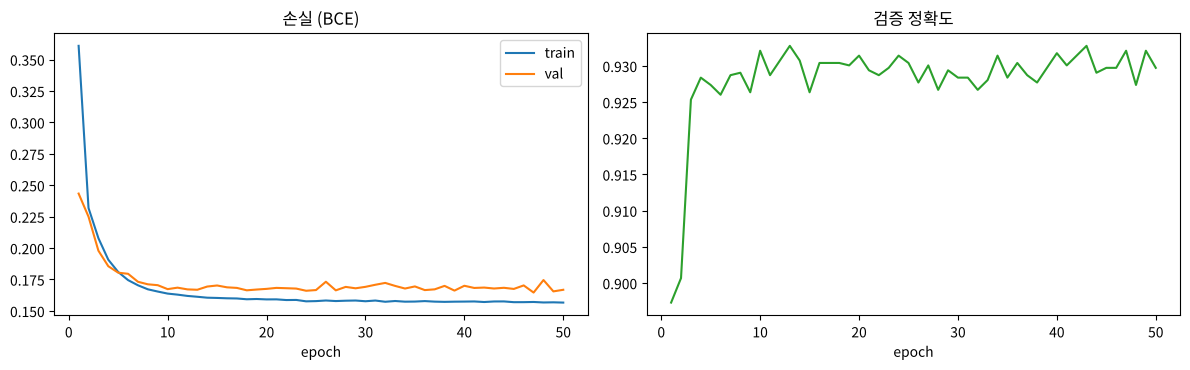

검증 손실 최저 에폭 : 47


In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
a1.plot(hist['epoch'], hist['train_loss'], label='train'); a1.plot(hist['epoch'], hist['val_loss'], label='val')
a1.set_title('손실 (BCE)'); a1.legend(); a1.set_xlabel('epoch')
a2.plot(hist['epoch'], hist['val_acc'], color='tab:green'); a2.set_title('검증 정확도'); a2.set_xlabel('epoch')
plt.tight_layout(); plt.show()
print('검증 손실 최저 에폭 :', int(hist.loc[hist['val_loss'].idxmin(), 'epoch']))

학습 손실은 첫 에폭 0.3 대 → 몇 에폭 만에 0.16 근처에서 멈춘다(팀 README '30 에폭 이후 약 0.153 수렴' 과 같은 모양). 검증 손실도 함께 평평해져 과대적합은 보이지 않는다 — 입력이 4개뿐이고 파라미터가 1,000개 정도라 외울 것이 많지 않다.

![학습 곡선 애니메이션](./images/anim_03_training_curve.gif)

## 3. 테스트 평가

In [7]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

def predict_proba(model, Xt):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(Xt)).numpy().ravel()

def metrics(y_true, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    return {'accuracy': accuracy_score(y_true, pred), 'precision': precision_score(y_true, pred),
            'recall': recall_score(y_true, pred), 'f1': f1_score(y_true, pred), 'roc_auc': roc_auc_score(y_true, prob)}

prob_mine = predict_proba(model, Xte_t)
print({k: round(v, 4) for k, v in metrics(y_test, prob_mine).items()})
print(confusion_matrix(y_test, prob_mine >= 0.5))
print(classification_report(y_test, prob_mine >= 0.5, target_names=['유지(0)', '이탈(1)'], digits=3))

{'accuracy': 0.9335, 'precision': 0.9237, 'recall': 0.956, 'f1': 0.9396, 'roc_auc': 0.9746}
[[3080  316]
 [ 176 3827]]
              precision    recall  f1-score   support

       유지(0)      0.946     0.907     0.926      3396
       이탈(1)      0.924     0.956     0.940      4003

    accuracy                          0.934      7399
   macro avg      0.935     0.931     0.933      7399
weighted avg      0.934     0.934     0.933      7399



## 4. 팀 모델(.pth) 직접 평가

- `.pth` 는 `torch.load(..., weights_only=True)` 로 **가중치(숫자)만** 읽는다 — 안전한 방식
- 전처리기 `.pkl` 은 열지 않았다 : pickle 은 열 때 코드가 실행될 수 있어 **믿을 수 있는 파일만** 열어야 하고, scikit-learn 1.6.1 로 저장돼 버전이 다르면 그대로는 안 열린다(`app.py` 도 우회 코드를 둠). 대신 **같은 분할의 학습 데이터로 같은 전처리기를 다시 fit** 해서 넣었다

In [8]:
ckpt = torch.load('team_project/models/mlp_churn_4features.pth', map_location='cpu', weights_only=True)
print({k: v for k, v in ckpt.items() if k != 'state_dict'})

team_model = build_mlp(ckpt['input_dim'], ckpt['hidden_dims'])
team_model.load_state_dict(ckpt['state_dict'])

pre_team = make_preprocessor().fit(X_train)           # app.py 평가와 같은 80% 학습 분할로 fit
prob_team = predict_proba(team_model, to_tensor(pre_team.transform(X_test)))
m_team = metrics(y_test, prob_team, ckpt['threshold'])
readme = {'accuracy': 0.938, 'precision': 0.945, 'recall': 0.940, 'f1': 0.942, 'roc_auc': 0.976}
pd.DataFrame({'팀 README': readme, '팀 모델 다시 평가': m_team, '다시 학습한 MLP': metrics(y_test, prob_mine)}).round(3)

{'input_dim': 11, 'hidden_dims': [32, 16], 'feature_columns': ['membership_category', 'points_in_wallet', 'avg_transaction_value', 'feedback_group'], 'target_col': 'churn_risk_score', 'threshold': 0.5}


,팀 README,팀 모델 다시 평가,다시 학습한 MLP
accuracy,0.938,0.935,0.934
precision,0.945,0.946,0.924
recall,0.940,0.933,0.956
f1,0.942,0.940,0.940
roc_auc,0.976,0.977,0.975


In [9]:
print('팀 모델 혼동 행렬 (다시 평가) :', confusion_matrix(y_test, prob_team >= 0.5).tolist())
print('팀 README 혼동 행렬          : [[3175, 221], [241, 3762]]')

팀 모델 혼동 행렬 (다시 평가) : [[3183, 213], [268, 3735]]
팀 README 혼동 행렬          : [[3175, 221], [241, 3762]]


- 저장된 팀 모델은 다시 평가해도 **정확도 0.935 · AUC 0.977** — README(0.938 · 0.976)와 거의 같다
- 혼동 행렬이 몇십 명 다른 것은 **학습 때의 분할 · 전처리 통계가 기록돼 있지 않기** 때문(`app.py` 의 `evaluation_note` 에도 같은 말이 있다). 학습 노트북에서 `random_state` · 분할 인덱스 · 전처리기를 **함께 저장**해 두면 숫자가 정확히 재현된다

> **📝 점검** — `app.py` 의 '모델 성능' 페이지는 현재 CSV 를 다시 80 : 20 으로 나눠 평가한다. 학습 때와 분할이 다르면 학습에 쓴 고객이 평가에 섞여 점수가 부풀 수 있다 → 테스트 인덱스를 저장해 두고 그 고객만 평가

## 5. 단순 모델과 비교 — MLP 가 꼭 필요했을까?

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text

Xtr_np, Xte_np = pre_team.transform(X_train), pre_team.transform(X_test)
rows = {}
rows['다수 클래스 (전부 이탈)'] = metrics(y_test, np.ones(len(y_test)))

# 사람이 만든 규칙 : 확실한 유지 조건 → 0, 그 밖에는 포인트 700 이하면 이탈
def rule(X):
    keep = X['membership_category'].isin(['Platinum Membership', 'Premium Membership']) \
           | (X['feedback_group'] == 'positive') | (X['avg_transaction_value'] > 50000)
    churn = X['membership_category'].isin(['No Membership', 'Basic Membership']) | (X['points_in_wallet'] <= 700)
    return np.where(keep, 0.0, np.where(churn, 1.0, 0.0))
rows['규칙 3줄'] = metrics(y_test, rule(X_test))

lr = LogisticRegression(max_iter=1000).fit(Xtr_np, y_train)
rows['로지스틱 회귀'] = metrics(y_test, lr.predict_proba(Xte_np)[:, 1])
for depth in [3, 4]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(Xtr_np, y_train)
    rows[f'결정 트리 (깊이 {depth})'] = metrics(y_test, tree.predict_proba(Xte_np)[:, 1])
rows['MLP (다시 학습)'] = metrics(y_test, prob_mine)
rows['MLP (팀 모델)'] = m_team
compare = pd.DataFrame(rows).T.round(3)
compare

,accuracy,precision,recall,f1,roc_auc
다수 클래스 (전부 이탈),0.541,0.541,1.000,0.702,0.500
규칙 3줄,0.931,0.927,0.946,0.937,0.929
로지스틱 회귀,0.914,0.945,0.894,0.919,0.966
결정 트리 (깊이 3),0.917,0.904,0.946,0.925,0.920
결정 트리 (깊이 4),0.931,0.927,0.946,0.936,0.945
MLP (다시 학습),0.934,0.924,0.956,0.940,0.975
MLP (팀 모델),0.935,0.946,0.933,0.940,0.977


- 다수 클래스 0.54 → **규칙 3줄**만으로도 정확도가 크게 오르고, **깊이 4 결정 트리**는 MLP 와 1%p 안쪽 차이
- 로지스틱 회귀가 뒤처지는 것은 포인트의 관계가 **계단 · 비단조**(EDA 4절)라 직선 하나로 못 나누기 때문 — 이 부분을 ReLU MLP · 트리가 잡는다
- 결론 : 이 데이터에서 MLP 의 장점은 '정확도 몇 %p' 보다 **확률이 부드럽게 나오는 것**(AUC 0.97)이고, 설명이 필요하면 트리가 더 낫다. 팀 소감(이승훈)처럼 '높은 정확도'보다 **기준 모델과의 차이**를 함께 보고해야 한다

In [11]:
tree3 = DecisionTreeClassifier(max_depth=3, random_state=42).fit(Xtr_np, y_train)
names = [n.split('__')[1] for n in pre_team.get_feature_names_out()]
print(export_text(tree3, feature_names=names, decimals=2))

|--- points_in_wallet <= 0.07
|   |--- feedback_group_positive <= 0.50
|   |   |--- membership_category_Premium Membership <= 0.50
|   |   |   |--- class: 1
|   |   |--- membership_category_Premium Membership >  0.50
|   |   |   |--- class: 0
|   |--- feedback_group_positive >  0.50
|   |   |--- class: 0
|--- points_in_wallet >  0.07
|   |--- membership_category_Basic Membership <= 0.50
|   |   |--- membership_category_No Membership <= 0.50
|   |   |   |--- class: 0
|   |   |--- membership_category_No Membership >  0.50
|   |   |   |--- class: 1
|   |--- membership_category_Basic Membership >  0.50
|   |   |--- points_in_wallet <= 0.16
|   |   |   |--- class: 1
|   |   |--- points_in_wallet >  0.16
|   |   |   |--- class: 1



트리의 첫 질문이 **포인트 ≤ 0.07**(표준화 값, 원래 단위로 약 700 점)이고 그 다음이 멤버십 · 피드백 — EDA 의 '계단' 을 그대로 찾아낸다. 사람이 만든 '규칙 3줄' 과 깊이 4 트리의 정확도가 0.931 로 같은 것도 이 때문이다.

## 6. 결정 경계 — Gold 멤버십 · 부정 피드백 고객

나머지 두 입력(포인트 · 평균 거래 금액)을 바꿔 가며 MLP 의 이탈 확률을 그려 보면 :

![결정 경계 애니메이션](./images/anim_04_decision_boundary.gif)

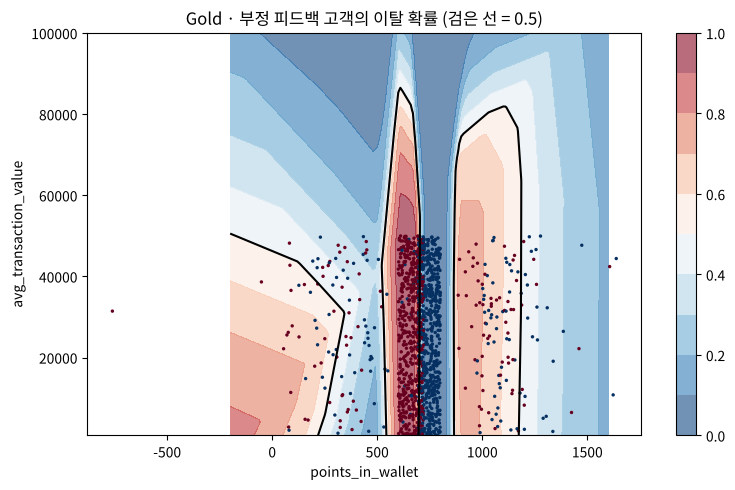

In [12]:
pts = np.linspace(-200, 1600, 181)
amt = np.linspace(800, 100000, 120)
P, T = np.meshgrid(pts, amt)
grid = pd.DataFrame({'membership_category': 'Gold Membership', 'points_in_wallet': P.ravel(),
                     'avg_transaction_value': T.ravel(), 'feedback_group': 'negative'})
Z = predict_proba(model, to_tensor(pre.transform(grid))).reshape(P.shape)

sub = df[(df['membership_category'] == 'Gold Membership') & (df['feedback_group'] == 'negative')].sample(1500, random_state=0)
fig, ax = plt.subplots(figsize=(8, 5))
cs = ax.contourf(P, T, Z, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.6)
ax.contour(P, T, Z, levels=[0.5], colors='k', linewidths=1.5)
ax.scatter(sub['points_in_wallet'], sub['avg_transaction_value'], c=sub[TARGET], cmap='RdBu_r', s=6, edgecolor='none')
ax.set_xlabel('points_in_wallet'); ax.set_ylabel('avg_transaction_value'); ax.set_title('Gold · 부정 피드백 고객의 이탈 확률 (검은 선 = 0.5)')
plt.colorbar(cs); plt.tight_layout(); plt.show()

In [13]:
# 거래 금액 25,000 에서 포인트만 바꿀 때 판정(0.5)이 바뀌는 지점
row = Z[np.argmin(np.abs(amt - 25000))]
flips = [int(round(pts[i])) for i in range(1, len(pts)) if (row[i] >= 0.5) != (row[i - 1] >= 0.5)]
print('판정이 바뀌는 포인트 :', flips)
print('구간별 판정 :', [('이탈' if row[np.searchsorted(pts, v)] >= 0.5 else '유지', v) for v in [0, 400, 650, 750, 950, 1300]])

판정이 바뀌는 포인트 : [330, 540, 710, 870, 1190]
구간별 판정 : [('이탈', 0), ('유지', 400), ('이탈', 650), ('유지', 750), ('이탈', 950), ('유지', 1300)]


- 거래 25,000 기준으로 포인트를 따라가면 판정이 **330 · 540 · 710 · 870 · 1,190점**에서 다섯 번 바뀐다 — 특히 **540~710점 이탈 → 710~870점 유지 → 870~1,190점 이탈** 띠가 뚜렷하다. EDA 4절의 비단조 관계를 MLP 가 꺾인 경계로 배웠다 (데이터가 적은 330점 아래 · 1,190점 위는 믿기 어렵다)
- 이 그룹에는 거래 금액 **5만 이상 고객이 한 명도 없다**(5만 초과는 전원 Platinum·Premium·긍정 피드백). 그래서 그 위쪽 확률은 데이터 없이 **외삽**한 값이라 믿으면 안 된다 — 모델은 본 적 없는 곳을 모른다

## 7. 변수를 하나씩 더하면 (팀 소감 : 변수 22 · 9 · 5개 비교와 같은 실험)

In [14]:
steps = [['membership_category'],
         ['membership_category', 'points_in_wallet'],
         ['membership_category', 'points_in_wallet', 'feedback_group'],
         FEATURES]
abl = []
for cols in steps:
    num = [c for c in cols if c in NUM]; cat = [c for c in cols if c in CAT]
    p_ = make_preprocessor(num, cat).fit(X_train[cols])
    xt, yt = to_tensor(p_.transform(X_train[cols]), y_train)
    m_, _ = train_mlp(xt, yt, epochs=15)
    pr = predict_proba(m_, to_tensor(p_.transform(X_test[cols])))
    abl.append({'입력': ' + '.join(c.split('_')[0] for c in cols), '입력 수': p_.transform(X_test[cols]).shape[1],
                **{k: round(v, 3) for k, v in metrics(y_test, pr).items()}})
ablation = pd.DataFrame(abl)
ablation

,입력,입력 수,accuracy,precision,recall,f1,roc_auc
0,membership,6,0.855,0.969,0.756,0.850,0.928
1,membership + points,7,0.926,0.929,0.934,0.931,0.973
2,membership + points + feedback,10,0.930,0.918,0.957,0.937,0.974
3,membership + points + avg + feedback,11,0.932,0.915,0.965,0.939,0.975


멤버십 하나로 이미 0.8 대, 포인트를 더하면 0.9 를 넘고, 피드백 · 거래 금액이 나머지를 채운다 — **멤버십 + 포인트 두 변수 의존**이 크다는 팀 결론과 같다.

## 8. 순열 중요도 (Day 031)

In [15]:
rng = np.random.default_rng(0)
base = accuracy_score(y_test, prob_mine >= 0.5)
imp = {}
for col in FEATURES:
    drops = []
    for _ in range(5):
        Xs = X_test.copy()
        Xs[col] = rng.permutation(Xs[col].values)                 # 한 열만 섞어서 정보를 끊기
        pr = predict_proba(model, to_tensor(pre.transform(Xs)))
        drops.append(base - accuracy_score(y_test, pr >= 0.5))
    imp[col] = np.mean(drops)
pd.Series(imp, name='정확도 감소 (5회 평균)').sort_values(ascending=False).round(3).to_frame()

,정확도 감소 (5회 평균)
membership_category,0.249
points_in_wallet,0.089
feedback_group,0.076
avg_transaction_value,0.001


- 멤버십을 섞으면 정확도가 **25%p**, 포인트 **9%p**, 피드백 **8%p** 떨어진다. **거래 금액은 0.1%p** — 5만 초과 고객이 전부 다른 조건과 겹쳐서 거의 쓸모가 없었다
- 팀 결론 '이탈 핵심 요인 : 멤버십 · 포인트 · 평균 이용 금액 · 피드백' 중 **평균 이용 금액은 빼도 된다** (7절 변수 추가 실험에서도 +0.2%p)

## 9. 임계값 — 이탈을 놓치지 않으려면

팀 모델은 0.5 를 넘으면 '이탈 위험' 으로 판정한다. 이탈 고객을 놓치는 비용(FN)이 크면 임계값을 낮춰 **재현율**을 올릴 수 있다.

![임계값 애니메이션](./images/anim_05_threshold.gif)

In [16]:
rows = []
for thr in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred = (prob_mine >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'임계값': thr, '정밀도': precision_score(y_test, pred), '재현율': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred), '놓친 이탈(FN)': fn, '잘못 경보(FP)': fp})
pd.DataFrame(rows).round(3)

,임계값,정밀도,재현율,F1,놓친 이탈(FN),잘못 경보(FP)
0,0.2,0.886,0.993,0.936,29,510
1,0.3,0.897,0.978,0.935,89,451
2,0.4,0.910,0.969,0.939,126,382
3,0.5,0.924,0.956,0.940,176,316
4,0.6,0.944,0.929,0.936,284,222
5,0.7,0.964,0.902,0.932,391,135
6,0.8,0.968,0.888,0.926,448,117


## 10. 대시보드 입력 점검 — 한 명 예측

In [17]:
# app.py '고객 이탈 예측' 페이지와 같은 계산 : 평균 거래 금액 = 누적 금액(만원) × 10,000 ÷ 횟수
def predict_customer(membership, points, total_manwon, count, feedback_group):
    one = pd.DataFrame([{'membership_category': membership, 'points_in_wallet': float(points),
                         'avg_transaction_value': total_manwon * 10_000 / count, 'feedback_group': feedback_group}])
    return float(predict_proba(model, to_tensor(pre.transform(one)))[0])

for args in [('Gold Membership', 720, 25, 10, 'negative'), ('Gold Membership', 650, 25, 10, 'negative'),
             ('Gold Membership', 650, 60, 1, 'negative'), ('Basic Membership', 800, 25, 10, 'positive')]:
    print(args, '→ 이탈 확률 %.3f' % predict_customer(*args))

('Gold Membership', 720, 25, 10, 'negative') → 이탈 확률 0.139
('Gold Membership', 650, 25, 10, 'negative') → 이탈 확률 0.942
('Gold Membership', 650, 60, 1, 'negative') → 이탈 확률 0.000
('Basic Membership', 800, 25, 10, 'positive') → 이탈 확률 0.000


> **📝 점검** (`app.py` 입력 폼)
> - 입력 이름이 **'보유 포인트 (만원)'** 인데 값은 변환 없이 그대로 `points_in_wallet` 에 들어간다 — 데이터의 포인트는 −760 ~ 2,069 범위의 **포인트 점수**라 '만원' 단위가 아니다. 라벨을 '보유 포인트(점)' 으로
> - 평균 거래 금액을 **원** 단위로 계산(만원 × 10,000)하는데, 데이터 출처(Hugging Face `d0r1h/customer_churn`)에도 금액 단위 설명이 없다(팀 README 도 '단위 추정'). 단위 가정을 화면에 적어 두면 오해가 줄어든다
> - 확률이 포인트 700 근처에서 급하게 바뀐다(650점 → 0.94, 720점 → 0.14) — 실제 서비스라면 '700 근처 고객' 에게 확신이 낮다는 표시를 함께 보여 주면 좋다

## 📝 점검 · 개선 제안 정리

| 항목 | 팀 프로젝트 | 제안 |
|---|---|---|
| 재현성 | 학습 분할 · 시드 · 전처리 통계 기록 없음 | 분할 인덱스 · `random_state` · 전처리기를 모델과 함께 저장 |
| 성능 페이지 | 현재 CSV 를 다시 나눠 평가 | 저장한 테스트 인덱스로만 평가 (학습 고객 섞임 방지) |
| 기준 모델 | MLP 단독 보고 | 규칙 · 로지스틱 · 결정 트리와 함께 보고 (규칙 3줄 · 트리 깊이 4 = 0.931 ≈ MLP 0.934) |
| 입력 변수 | 4개 | 평균 거래 금액은 순열 중요도 0.1%p — 3개로 줄여도 같은 성능 |
| 전처리기 저장 | `.pkl` (scikit-learn 1.6.1 고정) | 버전 고정(`requirements.txt` 에 `scikit-learn==1.6.1`) 또는 통계값을 JSON 으로 저장 |
| 포인트 | 중앙값 대체 · 음수 남음 | 결측 표시 열 추가 · 음수 → 결측 |
| 입력 폼 | 포인트 '(만원)' | 포인트 단위 표기 수정 |